# Gaseous transmittance: coupling with scattering

```{note}
This notebook is the first study of the coupling, made on SOS-ABS simulations in five absorption windows;
it led to the option `gas_coupling='effective_air_mass'`. Since version 1.1, the default of
{py:class}`~radcalnet_oc.process.Process` is the photon path-length model (`gas_coupling='path_length'`,
table `gas_coupling_ppld.csv`), fitted on simulations over 350-2500 nm (`scripts/sos_abs_coupling`, see
{ref}`methods-gas-coupling`); the decoupled model below is available with `gas_coupling='decoupled'`.
```

Before version 1.1, RadCalNet-OC computed the TOA signal **without gaseous absorption** (look-up tables of
the molecules and aerosols) and applied the gaseous transmittance afterwards, as for a direct beam:

$$R_{toa} = T_g(m)\,R_{atm} + T_g(m)\,t_d\,t_u\,\pi R_{rs}, \qquad
E_d = T_g(m_0)\,T_d\,E_0, \qquad m_0 = \frac{1}{\mu_0},\quad m = \frac{1}{\mu_0} + \frac{1}{\mu_v}$$

(`Tg_du` and `Tg_d` in {py:class}`~radcalnet_oc.process.Process`). This **decoupled** approach is exact
for the direct beam only. The scattered photons follow other paths:

- the skylight reaching the surface has longer slant paths than the direct beam: **more** absorption
  for the water-leaving term and the irradiance;
- the photons scattered by the molecules and aerosols **above** the absorbers shortcut part of the
  path: **less** absorption for the path reflectance, especially for the water vapour, concentrated in
  the lowest kilometres (scale height about 2 km), unlike the well-mixed O$_2$;
- multiple scattering lengthens the paths in both cases.

This notebook quantifies these effects with SOS-ABS simulations that **couple** absorption and scattering
(correlated-k distribution, 5 cm$^{-1}$), and derives an **effective air mass** for each term of the
signal, a correction that does not depend on the absorption table used by RadCalNet-OC (REPTRAN or
line by line).

In [1]:
import logging
import os

import matplotlib.pyplot as plt
rc = {"font.family": "serif",
      "mathtext.fontset": "stix"}
plt.rcParams.update(rc)
plt.rcParams["font.serif"] = ["Times New Roman"] + plt.rcParams["font.serif"]
plt.rcParams.update({'font.size': 16, 'axes.labelsize': 18})
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

import numpy as np
import pandas as pd
import xarray as xr

## Simulations

The look-up tables are made with `scripts/sos_abs_coupling/make_luts.py` (SOS-ABS Python package
`sosabs`), for the five absorption windows of the RadCalNet-OC spectral range:

| file | content | grid |
|---|---|---|
| `abs.nc` | TOA Stokes vector with absorption (CKD 5 cm$^{-1}$, H$_2$O 2 g cm$^{-2}$) | wl, sza (30°, 60°), AOT(550) (0.05, 0.2), albedo (0, 0.01, 0.03, 0.1) |
| `noabs.nc` | same without absorption | same |
| `tgdir_abs.nc`, `tgdir_noabs.nc` | direct flux at the surface with/without absorption | wl, 14 air masses from 1 to 10 |

Atmosphere: US62 molecules, WMO maritime aerosols (scale height 2 km); surface: rough sea (Cox-Munk,
5 m s$^{-1}$) + a Lambertian reflector of albedo $\rho$ standing for the water-leaving signal.
The set $(\theta_v, \phi)$ is limited to the Gauss angles $\theta_v \le 60°$, away from the sunglint
(glint angle $> 30°$), the glint being handled separately in RadCalNet-OC as direct light.

In [2]:
# scripts/sos_abs_coupling/data: link to the directory of the LUTs made by make_luts.py
DATA = os.environ.get('SOS_ABS_COUPLING_DIR', '../../../../scripts/sos_abs_coupling/data')

WINDOWS = {'O$_2$-B': (684, 698), 'H$_2$O 720': (712, 736), 'O$_2$-A': (757, 772),
           'H$_2$O 820': (808, 836), 'H$_2$O 940': (890, 990)}


def open_lut(name):
    ds = xr.open_dataset(f'{DATA}/{name}')
    return ds.assign_coords(wl=np.round(ds.wl.values * 1e3, 2))   # um -> nm


lut = {k: open_lut(f'{k}.nc') for k in ('abs', 'noabs')}
lut['abs']

<xarray.Dataset>
Dimensions:          (wl: 267, sza: 2, aot_ref: 2, albedo: 4, vza: 24, azi: 73)
Coordinates:
  * wl               (wl) float64 684.0 684.5 685.0 685.5 ... 988.0 989.0 990.0
  * sza              (sza) float64 30.0 60.0
  * aot_ref          (aot_ref) float64 0.05 0.2
  * albedo           (albedo) float64 0.0 0.01 0.03 0.1
  * vza              (vza) float64 2.841 6.521 10.22 13.93 ... 80.72 84.43 88.14
  * azi              (azi) float64 0.0 5.0 10.0 15.0 ... 345.0 350.0 355.0 360.0
    gauss_weight     (vza) float64 ...
    user_angle       (vza) int8 ...
Data variables: (12/13)
    I_up             (wl, sza, aot_ref, albedo, vza, azi) float32 ...
    Q_up             (wl, sza, aot_ref, albedo, vza, azi) float32 ...
    U_up             (wl, sza, aot_ref, albedo, vza, azi) float32 ...
    I_down           (wl, sza, aot_ref, albedo, vza, azi) float32 ...
    Q_down           (wl, sza, aot_ref, albedo, vza, azi) float32 ...
    U_down           (wl, sza, aot_ref, albedo, vza, azi) float32 ...
    ...               ...
    scat_angle_down  (wl, sza, aot_ref, albedo, vza, azi) float32 ...
    flux_dir_down    (wl, sza, aot_ref, albedo) float64 ...
    flux_diff_down   (wl, sza, aot_ref, albedo) float64 ...
    flux_tot_down    (wl, sza, aot_ref, albedo) float64 ...
    flux_diff_up     (wl, sza, aot_ref, albedo) float64 ...
    coef_tronca      (wl, sza, aot_ref, albedo) float64 ...
Attributes: (12/37)
    title:                   SOS-ABS look-up table
    source:                  SOS-ABS (Successive Orders of Scattering coupled...
    references:              Lenoble et al. (2007), JQSRT 107(3), doi:10.1016...
    sosabs_python_version:   0.1.0
    sos_backend:             f2py
    normalisation:           Stokes parameters normalised to the extraterrest...
    ...                      ...
    date_created:            2026-11-11T22:21:59+00:00
    history:                 2026-11-11 22:21:59 UTC: created by sosabs.build...
    lut_dimensions:          wl sza aot_ref albedo
    lut_keywords:            -SOS_Main.Wa -ANG.Thetas -AER.AOTref -SURF.Alb
    sos_code_version:        SOS-ABS version 5.1 (git c22446d-dirty)
    n_failed_runs:           0

### Direct transmittance $T_g(\lambda, m)$

The ratio of the direct fluxes with and without absorption is the band transmittance of the direct
beam for the air mass $m = 1/\mu_0$: this is what the decoupled model applies. For a correlated-k band
it is a sum of exponentials, not a single one: $-\ln T_g$ is not proportional to $m$ (saturation of
the strongest lines). The table is interpolated in $\ln T_g$ and inverted to get, for any effective
transmittance $T$, the **effective air mass** $m^*$ such that $T_g(m^*) = T$.

/home/harmel/anaconda3/lib/python3.9/site-packages/xarray/core/indexes.py:234: FutureWarning: Passing method to Float64Index.get_loc is deprecated and will raise in a future version. Use index.get_indexer([item], method=...) instead.
  indexer = self.index.get_loc(
/home/harmel/anaconda3/lib/python3.9/site-packages/xarray/core/indexes.py:234: FutureWarning: Passing method to Float64Index.get_loc is deprecated and will raise in a future version. Use index.get_indexer([item], method=...) instead.
  indexer = self.index.get_loc(
/home/harmel/anaconda3/lib/python3.9/site-packages/xarray/core/indexes.py:234: FutureWarning: Passing method to Float64Index.get_loc is deprecated and will raise in a future version. Use index.get_indexer([item], method=...) instead.
  indexer = self.index.get_loc(
/home/harmel/anaconda3/lib/python3.9/site-packages/xarray/core/indexes.py:234: FutureWarning: Passing method to Float64Index.get_loc is deprecated and will raise in a future version. Use index.get_index

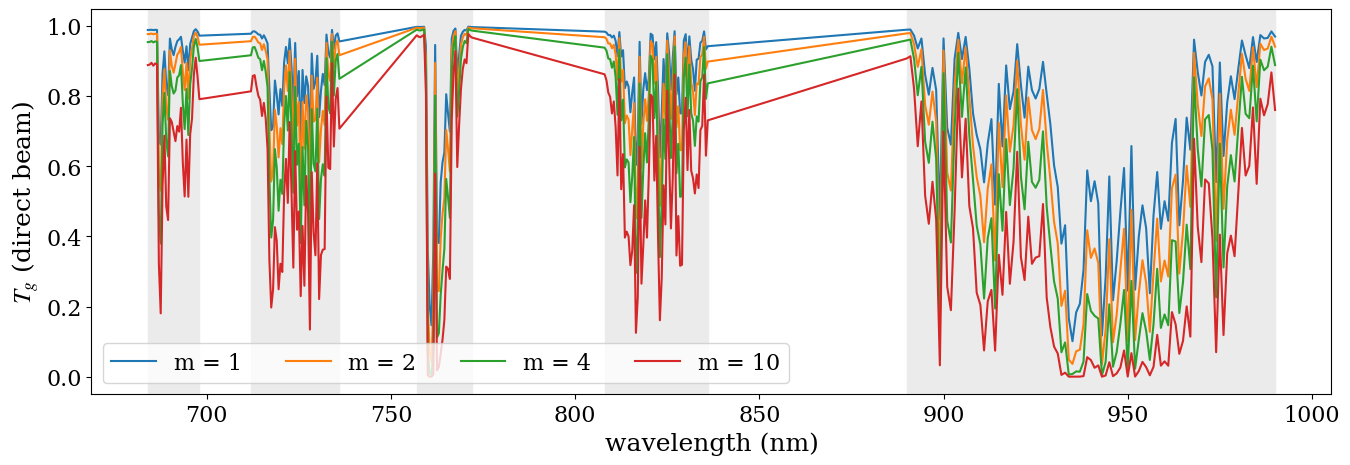

In [3]:
tg = (open_lut('tgdir_abs.nc').flux_dir_down / open_lut('tgdir_noabs.nc').flux_dir_down).squeeze(drop=True)
tg = tg.assign_coords(m=('sza', 1 / np.cos(np.radians(tg.sza.values)))).swap_dims(sza='m').drop_vars('sza')
tg = tg.sortby('m').transpose('wl', 'm')
lntg = np.log(tg)


def tg_of_m(m):
    '''Direct transmittance for the air mass m (DataArray with a wl dimension).'''
    return np.exp(lntg.interp(m=m))


def m_of_tg(t):
    '''Effective air mass m* such that Tg(m*) = t; nan outside the table or where Tg depends weakly on m.'''
    t = t.transpose('wl', ...)
    out = np.full(t.shape, np.nan)
    for i in range(tg.sizes['wl']):
        x = lntg.values[i][::-1]                       # increasing when m decreases
        if np.all(np.diff(x) > 0) and x[0] < np.log(0.99):
            out[i] = np.interp(np.log(t.values[i]), x, tg.m.values[::-1], left=np.nan, right=np.nan)
    return t.copy(data=out)


fig, ax = plt.subplots(figsize=(16, 5))
for m in (1, 2, 4, 10):
    tg.sel(m=m, method='nearest').plot(ax=ax, label=f'm = {m}')
for a, b in WINDOWS.values():
    ax.axvspan(a, b, color='0.92', zorder=-1)
ax.set(xlabel='wavelength (nm)', ylabel='$T_g$ (direct beam)', title='')
ax.legend(ncol=4)
plt.show()

## Decomposition of the TOA signal

For each geometry, the TOA reflectance $R = \pi L / (\mu_0 E_0)$ is split into a path term and a
surface term with the classical expression

$$R(\rho) = R_0 + \frac{\rho\,A}{1 - S\rho},$$

$R_0$ being the signal for a black surface (molecules, aerosols, skylight reflected by the sea), $A$
the product of the downward and upward total transmittances and $S$ the spherical albedo. $A$ and $S$
are fitted on the three albedos $\rho > 0$ (linear regression of $\rho/(R-R_0)$ on $\rho$), for the
simulations with and without absorption. The effective gaseous transmittances of each term are then

$$T_{atm} = \frac{R_0^{abs}}{R_0^{noabs}}, \qquad T_{w} = \frac{A^{abs}}{A^{noabs}}, \qquad
T_{Ed} = \frac{E_d^{abs}}{E_d^{noabs}} \;(\rho = 0),$$

to be compared with $T_g(m)$, $T_g(m)$ and $T_g(m_0)$ in RadCalNet-OC.

In [4]:
def decompose(ds):
    R = ds.I_up / np.cos(np.radians(ds.sza))
    R0 = R.sel(albedo=0)
    dR = (R - R0).sel(albedo=ds.albedo[ds.albedo > 0])
    y, x = dR.albedo / dR, dR.albedo               # y = 1/A - (S/A) rho
    xm, ym = x.mean(), y.mean('albedo')
    b = ((x - xm) * (y - ym)).sum('albedo') / ((x - xm) ** 2).sum()
    a = ym - b * xm
    A = 1 / a
    S = -b * A
    fit_err = (R0 + x * A / (1 - S * x)) / R.sel(albedo=x) - 1
    return xr.Dataset({'R': R, 'R0': R0, 'A': A, 'S': S, 'fit_err': fit_err})


dec = {k: decompose(lut[k]) for k in lut}

# geometries: Gauss angles <= 60 deg, glint angle > 30 deg
ds = lut['noabs']
mu0, muv = np.cos(np.radians(ds.sza)), np.cos(np.radians(ds.vza))
cos_glint = mu0 * muv + np.sqrt(1 - mu0 ** 2) * np.sqrt(1 - muv ** 2) * np.cos(np.radians(ds.azi))
valid = (ds.gauss_weight > 0) & (ds.vza <= 60) & (np.degrees(np.arccos(cos_glint)) > 30) & (ds.azi < 360)
m_geo = 1 / mu0 + 1 / muv

for k in dec:
    e = abs(dec[k].fit_err).where(valid)
    print(f'{k:6s} max relative error of the fit R0 + rho A / (1 - S rho): {float(e.max()):.1e}')

abs    max relative error of the fit R0 + rho A / (1 - S rho): 1.8e-06
noabs  max relative error of the fit R0 + rho A / (1 - S rho): 2.7e-05


/home/harmel/anaconda3/lib/python3.9/site-packages/xarray/core/missing.py:562: FutureWarning: Passing method to Float64Index.get_loc is deprecated and will raise in a future version. Use index.get_indexer([item], method=...) instead.
  imin = index.get_loc(minval, method="nearest")
/home/harmel/anaconda3/lib/python3.9/site-packages/xarray/core/missing.py:563: FutureWarning: Passing method to Float64Index.get_loc is deprecated and will raise in a future version. Use index.get_indexer([item], method=...) instead.
  imax = index.get_loc(maxval, method="nearest")
/home/harmel/anaconda3/lib/python3.9/site-packages/xarray/core/missing.py:562: FutureWarning: Passing method to Float64Index.get_loc is deprecated and will raise in a future version. Use index.get_indexer([item], method=...) instead.
  imin = index.get_loc(minval, method="nearest")
/home/harmel/anaconda3/lib/python3.9/site-packages/xarray/core/missing.py:563: FutureWarning: Passing method to Float64Index.get_loc is deprecated and 

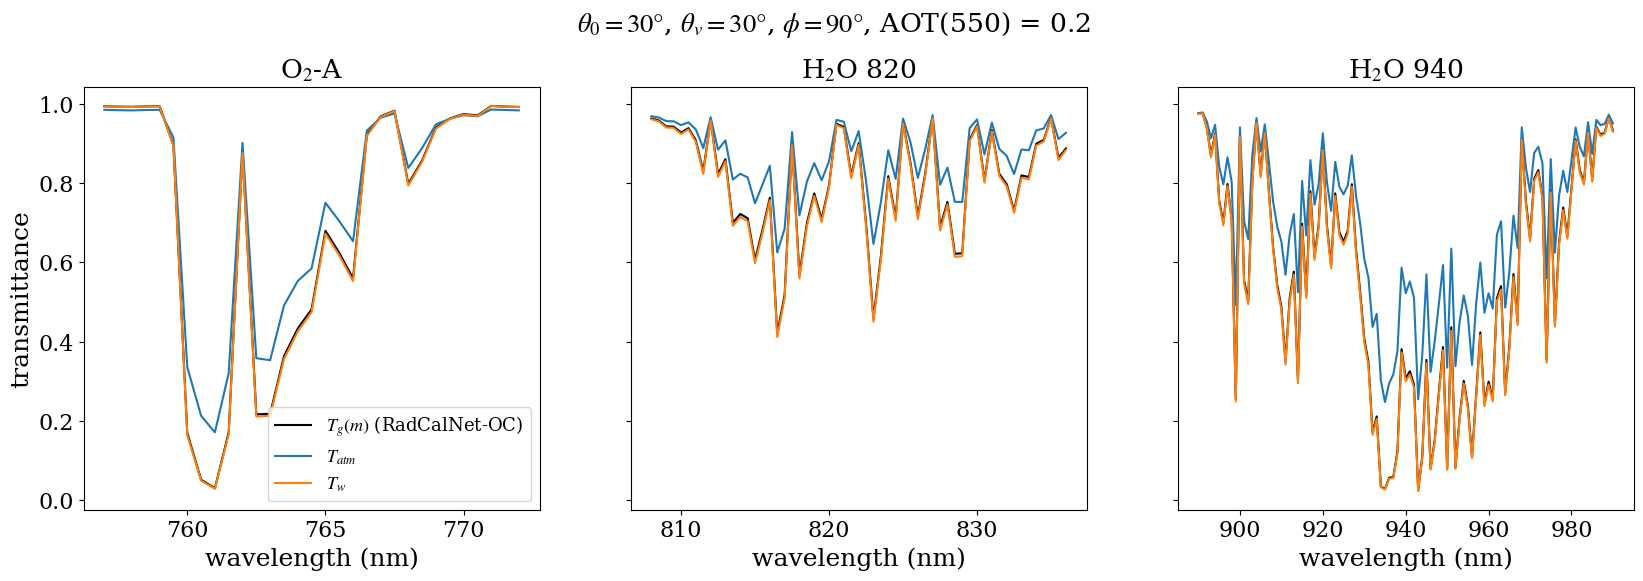

In [5]:
T = xr.Dataset({
    'Tatm': dec['abs'].R0 / dec['noabs'].R0,
    'Tw': dec['abs'].A / dec['noabs'].A,
})
T = T.where(valid)
fl = {k: lut[k].flux_tot_down.sel(albedo=0) for k in lut}
T_Ed = fl['abs'] / fl['noabs']

# decoupled model of RadCalNet-OC
T['Tg_m'] = tg_of_m(m_geo).where(valid)
T_Ed_model = tg_of_m(1 / mu0)


def window_stats(x, w):
    a, b = WINDOWS[w]
    return x.sel(wl=slice(a, b))


fig, axs = plt.subplots(1, 3, figsize=(20, 5.5), sharey=True)
sel = dict(sza=30, aot_ref=0.2, vza=ds.vza.sel(vza=30, method='nearest'), azi=90)
for ax, w in zip(axs, ['O$_2$-A', 'H$_2$O 820', 'H$_2$O 940']):
    t = window_stats(T.sel(**sel), w)
    t.Tg_m.plot(ax=ax, color='k', label='$T_g(m)$ (RadCalNet-OC)')
    t.Tatm.plot(ax=ax, color='tab:blue', label='$T_{atm}$')
    t.Tw.plot(ax=ax, color='tab:orange', label='$T_w$')
    ax.set(title=w, xlabel='wavelength (nm)', ylabel='')
axs[0].set_ylabel('transmittance')
axs[0].legend(fontsize=13)
fig.suptitle(r'$\theta_0 = 30°$, $\theta_v = 30°$, $\phi = 90°$, AOT(550) = 0.2', y=1.02)
plt.show()

## Effective air masses

The effective air mass of each term, normalised by the geometric one, measures the coupling
independently of the absorption strength:

$$\eta_{atm} = \frac{m^*(T_{atm})}{m}, \qquad \eta_w = \frac{m^*(T_w)}{m}, \qquad
\eta_{Ed} = \frac{m^*(T_{Ed})}{m_0}.$$

$\eta = 1$ is the decoupled model. $\eta$ is only defined where the absorption is significant: the
channels with $T_g(m) < 0.95$ are kept.

In [6]:
strong = T.Tg_m < 0.95
eta = xr.Dataset({
    'atm': (m_of_tg(T.Tatm) / m_geo).where(strong),
    'w': (m_of_tg(T.Tw) / m_geo).where(strong),
})
eta_Ed = (m_of_tg(T_Ed) / (1 / mu0)).where(T_Ed_model < 0.95)

rows = []
for w in WINDOWS:
    r = {'window': w}
    for k in ('atm', 'w'):
        e = window_stats(eta[k], w)
        r[f'eta_{k} median'] = float(e.median())
        r[f'eta_{k} 5-95%'] = f'{float(e.quantile(0.05)):.2f} - {float(e.quantile(0.95)):.2f}'
    e = window_stats(eta_Ed, w)
    r['eta_Ed median'] = float(e.median())
    rows.append(r)
pd.DataFrame(rows).set_index('window').round(3)

,eta_atm median,eta_atm 5-95%,eta_w median,eta_w 5-95%,eta_Ed median
window,,,,,
O$_2$-B,0.664,0.44 - 0.90,1.040,1.03 - 1.07,1.035
H$_2$O 720,0.555,0.35 - 0.87,1.043,1.03 - 1.07,1.041
O$_2$-A,0.572,0.35 - 0.89,1.025,1.01 - 1.06,1.023
H$_2$O 820,0.562,0.36 - 0.88,1.039,1.02 - 1.07,1.037
H$_2$O 940,0.518,0.34 - 0.82,1.023,1.01 - 1.06,1.021


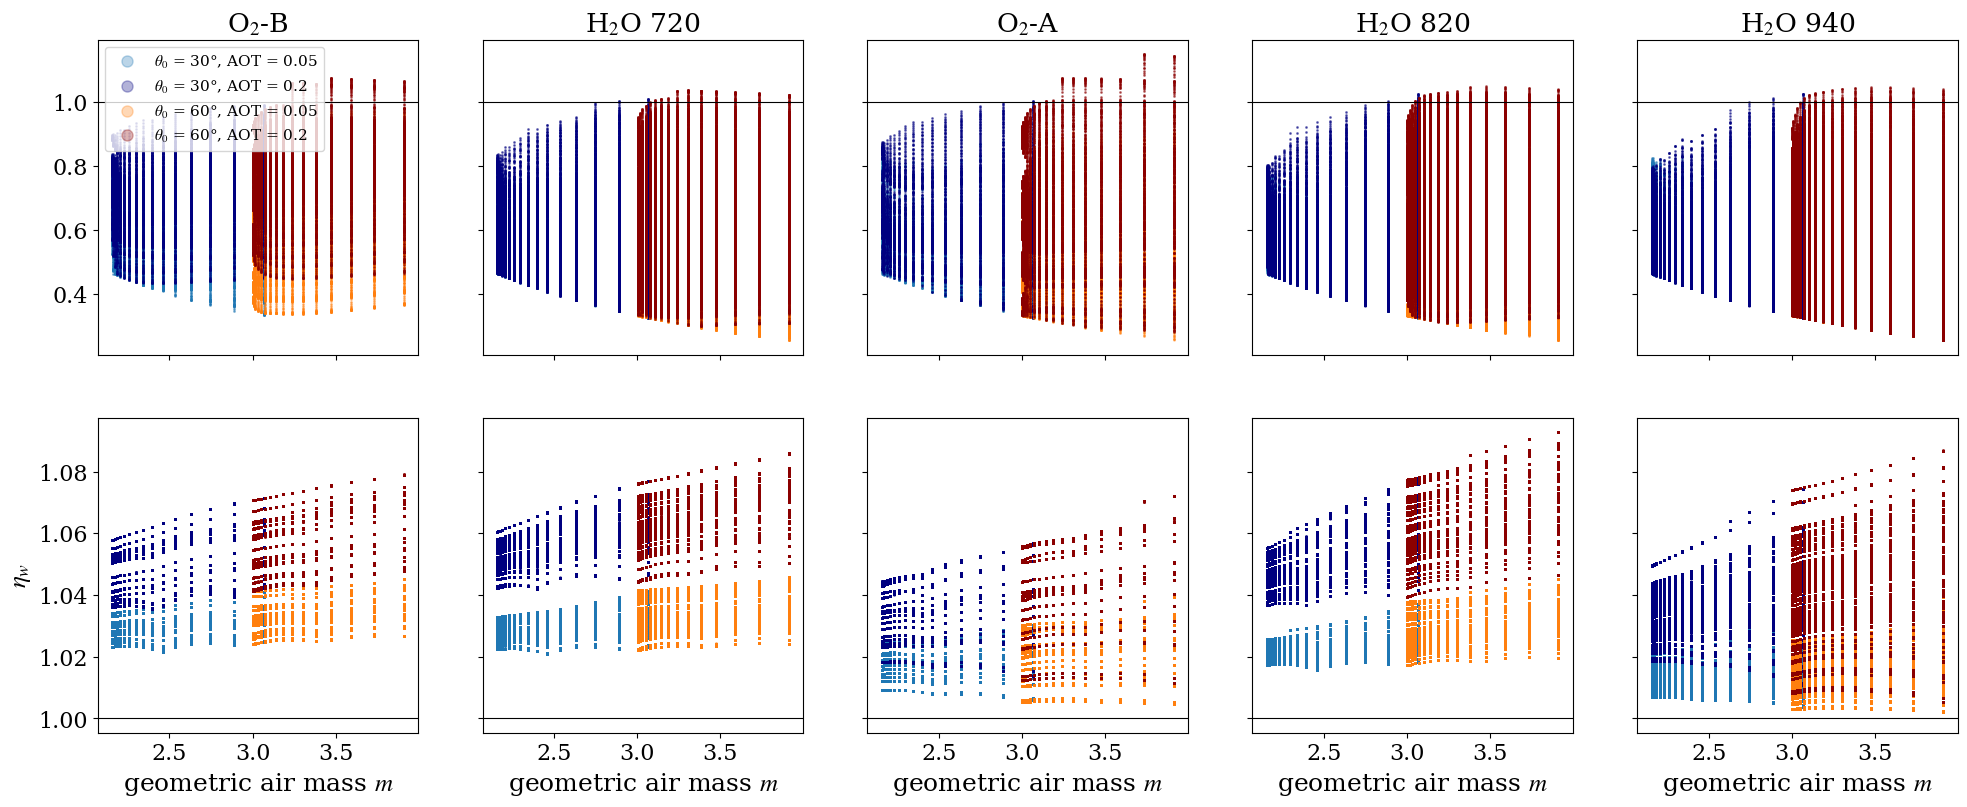

In [7]:
fig, axs = plt.subplots(2, 5, figsize=(24, 9), sharex=True, sharey='row')
colors = {(30, 0.05): 'tab:blue', (30, 0.2): 'navy', (60, 0.05): 'tab:orange', (60, 0.2): 'darkred'}
for j, w in enumerate(WINDOWS):
    for i, k in enumerate(('atm', 'w')):
        ax = axs[i, j]
        e = window_stats(eta[k], w)
        for (sza, aot), c in colors.items():
            x = e.sel(sza=sza, aot_ref=aot)
            mm = m_geo.sel(sza=sza).broadcast_like(x)
            ax.plot(mm.values.ravel(), x.values.ravel(), '.', ms=2, alpha=0.3, color=c,
                    label=fr'$\theta_0$ = {sza}°, AOT = {aot}')
        ax.axhline(1, color='k', lw=0.8)
        if i == 0:
            ax.set_title(w)
        if i == 1:
            ax.set_xlabel('geometric air mass $m$')
    axs[i, 0].set_ylabel(fr'$\eta_{{{k}}}$')
axs[0, 0].legend(markerscale=8, fontsize=11)
plt.show()

## Parameterization

A simple correction of the air mass is fitted per absorption window and per term, linear in the
geometric air mass and the aerosol optical thickness:

$$\eta = c_0 + c_1\,(m - 2) + c_2\,(\tau_{550} - 0.1),$$

each channel being weighted by its absorption $1 - T_g(m)$, so that the fit is driven by the
channels where the correction matters.

In [8]:
def fit_eta(e, m, aot, weight):
    e, m, aot, weight = xr.broadcast(e, m, aot, weight)
    ok = np.isfinite(e.values) & np.isfinite(weight.values)
    X = np.c_[np.ones(ok.sum()), m.values[ok] - 2, aot.values[ok] - 0.1]
    sw = np.sqrt(weight.values[ok])
    c, *_ = np.linalg.lstsq(X * sw[:, None], e.values[ok] * sw, rcond=None)
    res = e.values[ok] - X @ c
    return c, np.sqrt(np.average(res ** 2, weights=weight.values[ok]))


coefs = {}
rows = []
for w in WINDOWS:
    for k in ('atm', 'w'):
        e = window_stats(eta[k], w)
        c, rms = fit_eta(e, m_geo, e.aot_ref, 1 - window_stats(T.Tg_m, w))
        coefs[(w, k)] = c
        rows.append({'window': w, 'term': k, 'c0': c[0], 'c1': c[1], 'c2': c[2], 'rms': rms})
pd.DataFrame(rows).set_index(['window', 'term']).round(3)

c0     c1     c2    rms
window     term                            
O$_2$-B    atm   0.568  0.034  0.915  0.115
           w     1.031  0.006  0.137  0.007
H$_2$O 720 atm   0.512 -0.022  0.504  0.131
           w     1.033  0.007  0.184  0.006
O$_2$-A    atm   0.520 -0.026  0.674  0.122
           w     1.018  0.002  0.099  0.009
H$_2$O 820 atm   0.521 -0.016  0.570  0.134
           w     1.026  0.008  0.194  0.006
H$_2$O 940 atm   0.549 -0.063  0.205  0.127
           w     1.017  0.003  0.136  0.009

### Coefficients of the first version

The irradiance term is fitted in the same way in $m_0 = 1/\mu_0$. These coefficients were the first
version of the table of the package. The table now used by {py:class}`~radcalnet_oc.kernel.GasCoupling`
(option `gas_coupling='effective_air_mass'` of {py:class}`~radcalnet_oc.process.Process`,
`radcalnet_oc/data/auxdata/gas_coupling_eta.csv`) is fitted on an extended set of simulations (water
vapour column, solar angle, aerosol load) by `scripts/sos_abs_coupling/coupling.py`, with a
single-scattering blend for the path reflectance (see the notes at the end).

In [9]:
NAMES = {'O$_2$-B': 'O2-B', 'H$_2$O 720': 'H2O-720', 'O$_2$-A': 'O2-A', 'H$_2$O 820': 'H2O-820',
         'H$_2$O 940': 'H2O-940'}
m_range = {'atm': m_geo.where(valid), 'w': m_geo.where(valid), 'Ed': 1 / mu0}
rows = []
for w, (a, b) in WINDOWS.items():
    e = window_stats(eta_Ed, w)
    c, rms = fit_eta(e, 1 / mu0, e.aot_ref, 1 - window_stats(T_Ed_model, w))
    coefs[(w, 'Ed')] = c
    for k in ('atm', 'w', 'Ed'):
        c = coefs[(w, k)]
        rows.append({'window': NAMES[w], 'wl_min': a, 'wl_max': b, 'term': k,
                     'c0': c[0], 'c1': c[1], 'c2': c[2],
                     'm_min': float(m_range[k].min()), 'm_max': float(m_range[k].max()),
                     'aot_min': float(T.aot_ref.min()), 'aot_max': float(T.aot_ref.max())})
table = pd.DataFrame(rows)

table.set_index(['window', 'term']).round(3)

wl_min  wl_max     c0     c1     c2  m_min  m_max  aot_min  \
window  term                                                               
O2-B    atm      684     698  0.568  0.034  0.915  2.156  3.911     0.05   
        w        684     698  1.031  0.006  0.137  2.156  3.911     0.05   
        Ed       684     698  1.037  0.010  0.128  1.155  2.000     0.05   
H2O-720 atm      712     736  0.512 -0.022  0.504  2.156  3.911     0.05   
        w        712     736  1.033  0.007  0.184  2.156  3.911     0.05   
        Ed       712     736  1.038  0.010  0.166  1.155  2.000     0.05   
O2-A    atm      757     772  0.520 -0.026  0.674  2.156  3.911     0.05   
        w        757     772  1.018  0.002  0.099  2.156  3.911     0.05   
        Ed       757     772  1.017  0.001  0.087  1.155  2.000     0.05   
H2O-820 atm      808     836  0.521 -0.016  0.570  2.156  3.911     0.05   
        w        808     836  1.026  0.008  0.194  2.156  3.911     0.05   
        Ed       808     836  1.035  0.012  0.173  1.155  2.000     0.05   
H2O-940 atm      890     990  0.549 -0.063  0.205  2.156  3.911     0.05   
        w        890     990  1.017  0.003  0.136  2.156  3.911     0.05   
        Ed       890     990  1.017  0.001  0.112  1.155  2.000     0.05   

              aot_max  
window  term           
O2-B    atm       0.2  
        w         0.2  
        Ed        0.2  
H2O-720 atm       0.2  
        w         0.2  
        Ed        0.2  
O2-A    atm       0.2  
        w         0.2  
        Ed        0.2  
H2O-820 atm       0.2  
        w         0.2  
        Ed        0.2  
H2O-940 atm       0.2  
        w         0.2  
        Ed        0.2

### A physically based form for the path reflectance

$\eta_{atm} \approx 0.5$ has a simple explanation: in single scattering, when the absorber and the
scatterers have the same vertical distribution (O$_2$ and the molecules), the photons scattered at a
level where a fraction $x$ of the column lies above see the absorber amount $x\,m$, and averaging over
$x$ uniform in $[0, 1]$ gives

$$T_{ss} = \int_0^1 e^{-x\,\tau m}\,dx = \frac{1 - T_g(m)}{-\ln T_g(m)},$$

an effective air mass of $m/2$ for a weak absorption, and less when it saturates; this explains
the spread of $\eta_{atm}$ in the figure above. The skylight reflected by the surface and the
aerosols, close to the surface, see the whole path. A one-parameter blend per window and aerosol load,

$$T_{atm} = T_{ss}^{\,k}\;T_g(m)^{1-k},$$

follows the simulations better than the linear correction of $\eta$:

In [10]:
Tm = tg_of_m(m_geo).where(valid)
Tss = (1 - Tm) / (-np.log(Tm))
kblend = {}
rows = []
for w in WINDOWS:
    ta, tm, ts = xr.broadcast(*(window_stats(x, w) for x in (T.Tatm, Tm, Tss)))
    msk = tm < 0.95
    k = []
    for aot in ta.aot_ref.values:
        s = dict(aot_ref=aot)
        y = np.log(ta / tm).sel(**s).where(msk.sel(**s))
        x = np.log(ts / tm).sel(**s).where(msk.sel(**s))
        k.append(float((x * y).sum() / (x * x).sum()))
    k = xr.DataArray(k, coords={'aot_ref': ta.aot_ref}, dims='aot_ref')
    kblend[w] = k
    row = {'window': w, 'k (AOT 0.05)': k.values[0], 'k (AOT 0.2)': k.values[1]}
    for name, model in (('Tg(m)', tm), ('Tss', ts), ('blend', ts ** k * tm ** (1 - k))):
        e = (abs(model / ta - 1) * 100).where(msk)
        row[f'{name} median (%)'] = float(e.median())
        row[f'{name} p95 (%)'] = float(e.quantile(0.95))
    rows.append(row)
pd.DataFrame(rows).set_index('window').round(2)

/home/harmel/anaconda3/lib/python3.9/site-packages/xarray/core/missing.py:562: FutureWarning: Passing method to Float64Index.get_loc is deprecated and will raise in a future version. Use index.get_indexer([item], method=...) instead.
  imin = index.get_loc(minval, method="nearest")
/home/harmel/anaconda3/lib/python3.9/site-packages/xarray/core/missing.py:563: FutureWarning: Passing method to Float64Index.get_loc is deprecated and will raise in a future version. Use index.get_indexer([item], method=...) instead.
  imax = index.get_loc(maxval, method="nearest")


,k (AOT 0.05),k (AOT 0.2),Tg(m) median (%),Tg(m) p95 (%),Tss median (%),Tss p95 (%),blend median (%),blend p95 (%)
window,,,,,,,,
O$_2$-B,0.67,0.45,4.30,19.72,3.87,17.83,1.25,5.39
H$_2$O 720,1.06,0.79,11.28,33.08,2.54,10.02,1.79,7.46
O$_2$-A,0.90,0.72,19.26,89.43,11.92,66.70,5.70,29.19
H$_2$O 820,1.01,0.72,9.23,30.15,2.59,11.42,1.66,7.80
H$_2$O 940,1.11,0.92,24.98,88.05,5.70,35.20,4.29,29.19


## Impact on the TOA reflectance

Relative error of the TOA reflectance for $\rho = 0.01$ (bright water) and $\rho = 0$ when the
absorption is applied after the scattering computation, with the geometric air mass (RadCalNet-OC) or
with the effective one:

$$R^{model} = T_g(\eta_{atm} m)\,R_0^{noabs} + T_g(\eta_w m)\,\frac{\rho A^{noabs}}{1 - S^{noabs}\rho}$$

compared with the coupled simulation $R^{abs}(\rho)$.

In [11]:
def eta_param(k):
    '''Fitted eta on the LUT grid; 1 (decoupled model) outside the absorption windows.'''
    out = xr.ones_like(T.wl * m_geo * T.aot_ref, dtype=float)
    for w, (a, b) in WINDOWS.items():
        c = coefs[(w, k)]
        e = c[0] + c[1] * (m_geo - 2) + c[2] * (T.aot_ref - 0.1)
        out = xr.where((T.wl >= a) & (T.wl <= b), e, out)
    return out


N = dec['noabs']
results = {}
for rho in (0., 0.01):
    Rtrue = dec['abs'].R.sel(albedo=rho)
    surf = rho * N.A / (1 - N.S * rho)
    R_dec = tg_of_m(m_geo) * (N.R0 + surf)
    R_par = tg_of_m(eta_param('atm') * m_geo) * N.R0 + tg_of_m(eta_param('w') * m_geo) * surf
    results[rho] = {'decoupled': (R_dec / Rtrue - 1).where(valid),
                    'effective air mass': (R_par / Rtrue - 1).where(valid)}

rows = []
for w in WINDOWS:
    for rho, r in results.items():
        row = {'window': w, 'rho': rho}
        for k, err in r.items():
            e = abs(window_stats(err, w)) * 100
            row[f'{k} median (%)'] = float(e.median())
            row[f'{k} p99 (%)'] = float(e.quantile(0.99))
        rows.append(row)
pd.DataFrame(rows).set_index(['window', 'rho']).round(2)

/home/harmel/anaconda3/lib/python3.9/site-packages/xarray/core/missing.py:562: FutureWarning: Passing method to Float64Index.get_loc is deprecated and will raise in a future version. Use index.get_indexer([item], method=...) instead.
  imin = index.get_loc(minval, method="nearest")
/home/harmel/anaconda3/lib/python3.9/site-packages/xarray/core/missing.py:563: FutureWarning: Passing method to Float64Index.get_loc is deprecated and will raise in a future version. Use index.get_indexer([item], method=...) instead.
  imax = index.get_loc(maxval, method="nearest")
/home/harmel/anaconda3/lib/python3.9/site-packages/xarray/core/missing.py:562: FutureWarning: Passing method to Float64Index.get_loc is deprecated and will raise in a future version. Use index.get_indexer([item], method=...) instead.
  imin = index.get_loc(minval, method="nearest")
/home/harmel/anaconda3/lib/python3.9/site-packages/xarray/core/missing.py:563: FutureWarning: Passing method to Float64Index.get_loc is deprecated and 

decoupled median (%)  decoupled p99 (%)  \
window     rho                                             
O$_2$-B    0.00                  2.75              25.43   
           0.01                  2.10              20.66   
H$_2$O 720 0.00                 10.21              41.28   
           0.01                  7.89              34.55   
O$_2$-A    0.00                  2.76              93.36   
           0.01                  1.93              90.88   
H$_2$O 820 0.00                  8.51              42.64   
           0.01                  6.06              33.46   
H$_2$O 940 0.00                 23.76              95.80   
           0.01                 16.55              93.43   

                 effective air mass median (%)  effective air mass p99 (%)  
window     rho                                                              
O$_2$-B    0.00                           1.51                        8.37  
           0.01                           1.19                        7.16  
H$_2$O 720 0.00                           2.31                       17.77  
           0.01                           1.86                       15.04  
O$_2$-A    0.00                           1.66                       60.27  
           0.01                           1.31                       58.73  
H$_2$O 820 0.00                           2.14                       20.28  
           0.01                           1.59                       15.92  
H$_2$O 940 0.00                           6.47                       78.20  
           0.01                           4.70                       76.06

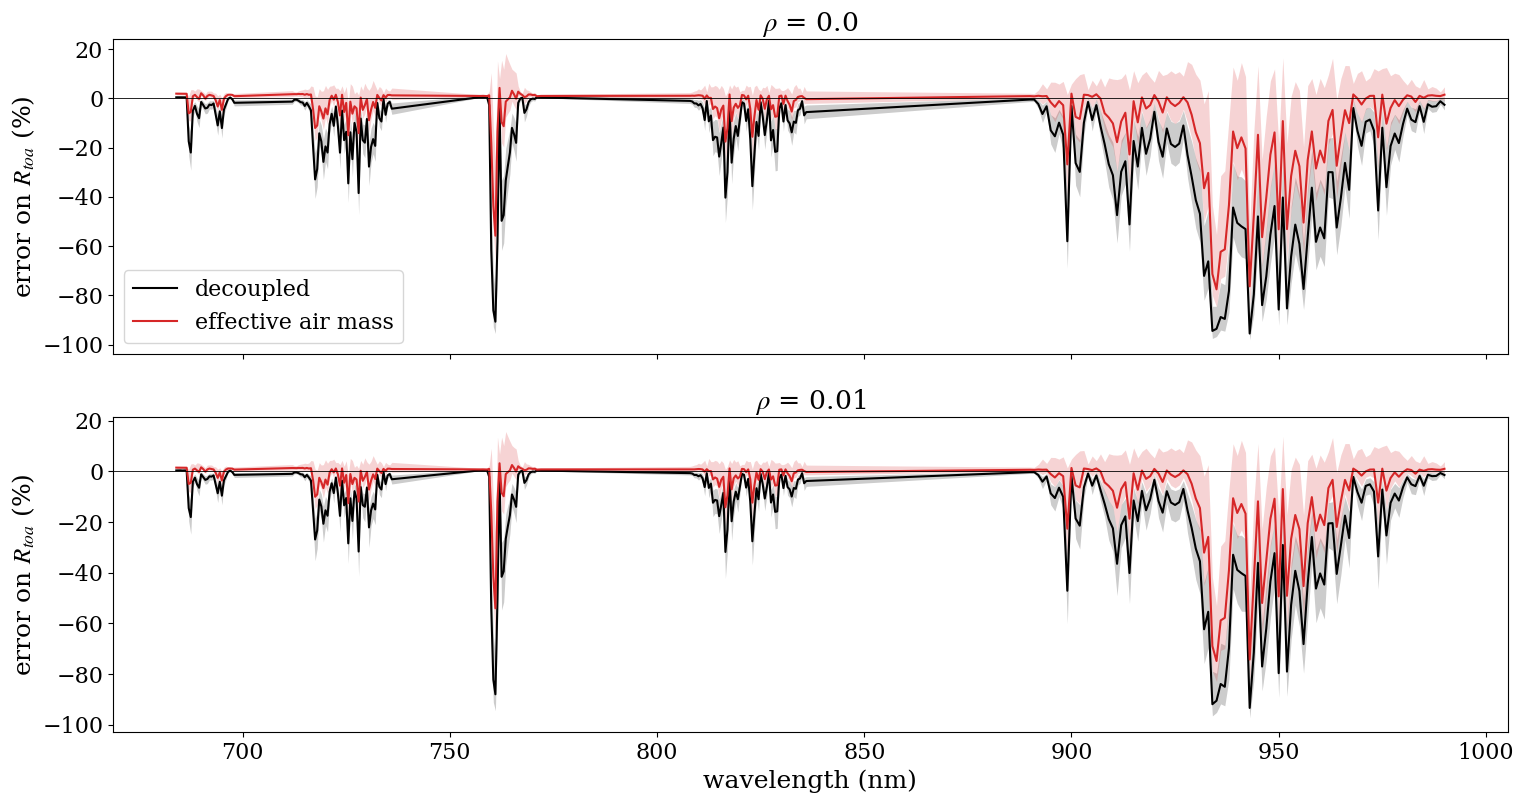

In [12]:
fig, axs = plt.subplots(2, 1, figsize=(18, 9), sharex=True)
for ax, rho in zip(axs, (0., 0.01)):
    for k, c in (('decoupled', 'k'), ('effective air mass', 'tab:red')):
        err = results[rho][k] * 100
        st = err.stack(g=[d for d in err.dims if d != 'wl'])
        ax.fill_between(st.wl, st.quantile(0.05, 'g'), st.quantile(0.95, 'g'), color=c, alpha=0.2, lw=0)
        st.median('g').plot(ax=ax, color=c, label=k)
    ax.axhline(0, color='k', lw=0.6)
    ax.set(title=fr'$\rho$ = {rho}', xlabel='', ylabel='error on $R_{toa}$ (%)')
axs[0].legend()
axs[1].set_xlabel('wavelength (nm)')
plt.show()

## Notes and next steps

- **Main result**: the path reflectance sees about **half** the geometric air mass
  ($\eta_{atm} \approx 0.5$-$0.65$), while the water-leaving term and the irradiance see 2-4 % more
  ($\eta_w, \eta_{Ed} \approx 1.02$-$1.04$). Applying $T_g(1/\mu_0 + 1/\mu_v)$ to $R_{atm}$, as done before version 1.1,
  underestimates the TOA reflectance by several % to tens of % in the absorption bands.
- The linear correction of $\eta$ is enough for the water term; for $R_{atm}$ the single-scattering
  blend $T_{ss}^k T_g^{1-k}$ is the better candidate (one coefficient per window, depending on the
  aerosol load), to be refined with more simulations.

- The water vapour content is fixed (2 g cm$^{-2}$): $\eta$ may depend on it through the saturation of
  the bands and the vertical profile; a LUT dimension `-AP.H2O` (e.g. 0.5, 2, 4 g cm$^{-2}$) would
  test it. The same holds for the surface pressure for O$_2$.
- Only two solar angles and two aerosol loads are simulated; the fit in $m$ relies mostly on the
  viewing angle. More `sza` values (e.g. 20°, 40°, 50°, 70°) would make the parameterization safer.
- The correction is implemented in RadCalNet-OC: option `gas_coupling='effective_air_mass'` of
  {py:class}`~radcalnet_oc.process.Process` (transmittances `Tg_atm`, `Tg_w` and `Tg_Ed` of `Ratm`, of the
  water-leaving term and of `Ed`, {py:class}`~radcalnet_oc.kernel.GasCoupling`); the default was then the
  decoupled model. The coefficients of the package come from an extended set of simulations (H$_2$O
  column 0.5-4 g cm$^{-2}$, four solar angles, three aerosol loads, `make_luts.py v2`), with the direct
  sunglint removed from $R_0$, seven windows (O$_2$-A and 940 nm bands split), the single-scattering
  blend for the path reflectance in the O$_2$-A head and the 940 nm core, and fits weighted for the
  absolute transmittance error. As the fit is
  made on 5 cm$^{-1}$ CKD intervals, the package computes the correction on its transmittance smoothed to
  5 cm$^{-1}$ and applies it channel by channel keeping the interval means: applied directly to the much
  more saturated REPTRAN channels, the blend over-corrects the 940 nm band by a factor of several.
- The CKD bands are 5 cm$^{-1}$ wide; after convolution with a sensor spectral response, the same
  analysis should be redone at the band level, the effective air mass of a band average differing
  from the average of the per-channel ones in the saturated bands.
- Since version 1.1, the default is the photon path-length model (`gas_coupling='path_length'`), applied channel by channel without smoothing, with coefficients fitted over 350-2500 nm (`scripts/sos_abs_coupling/ppld.py`).